# Seq-to-Seq Models

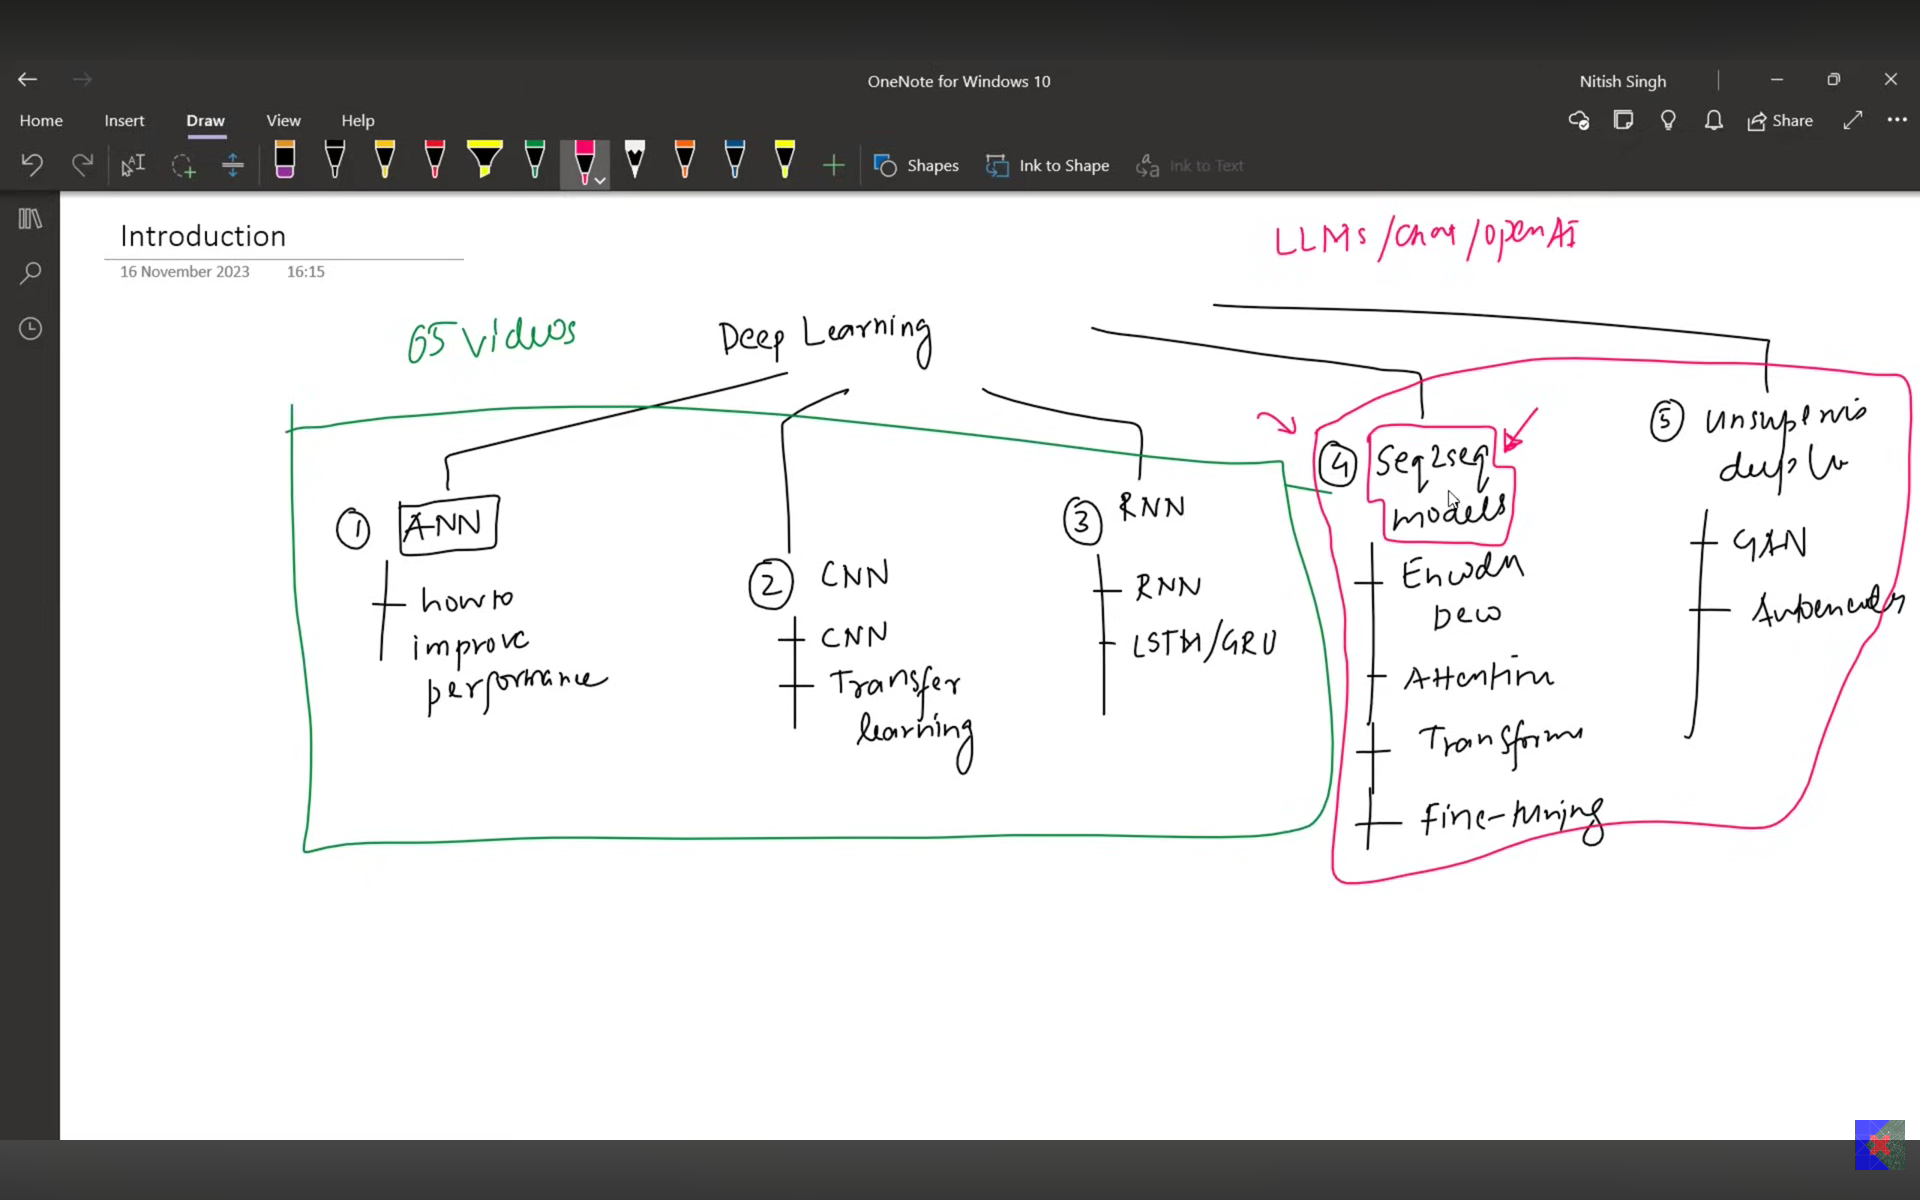

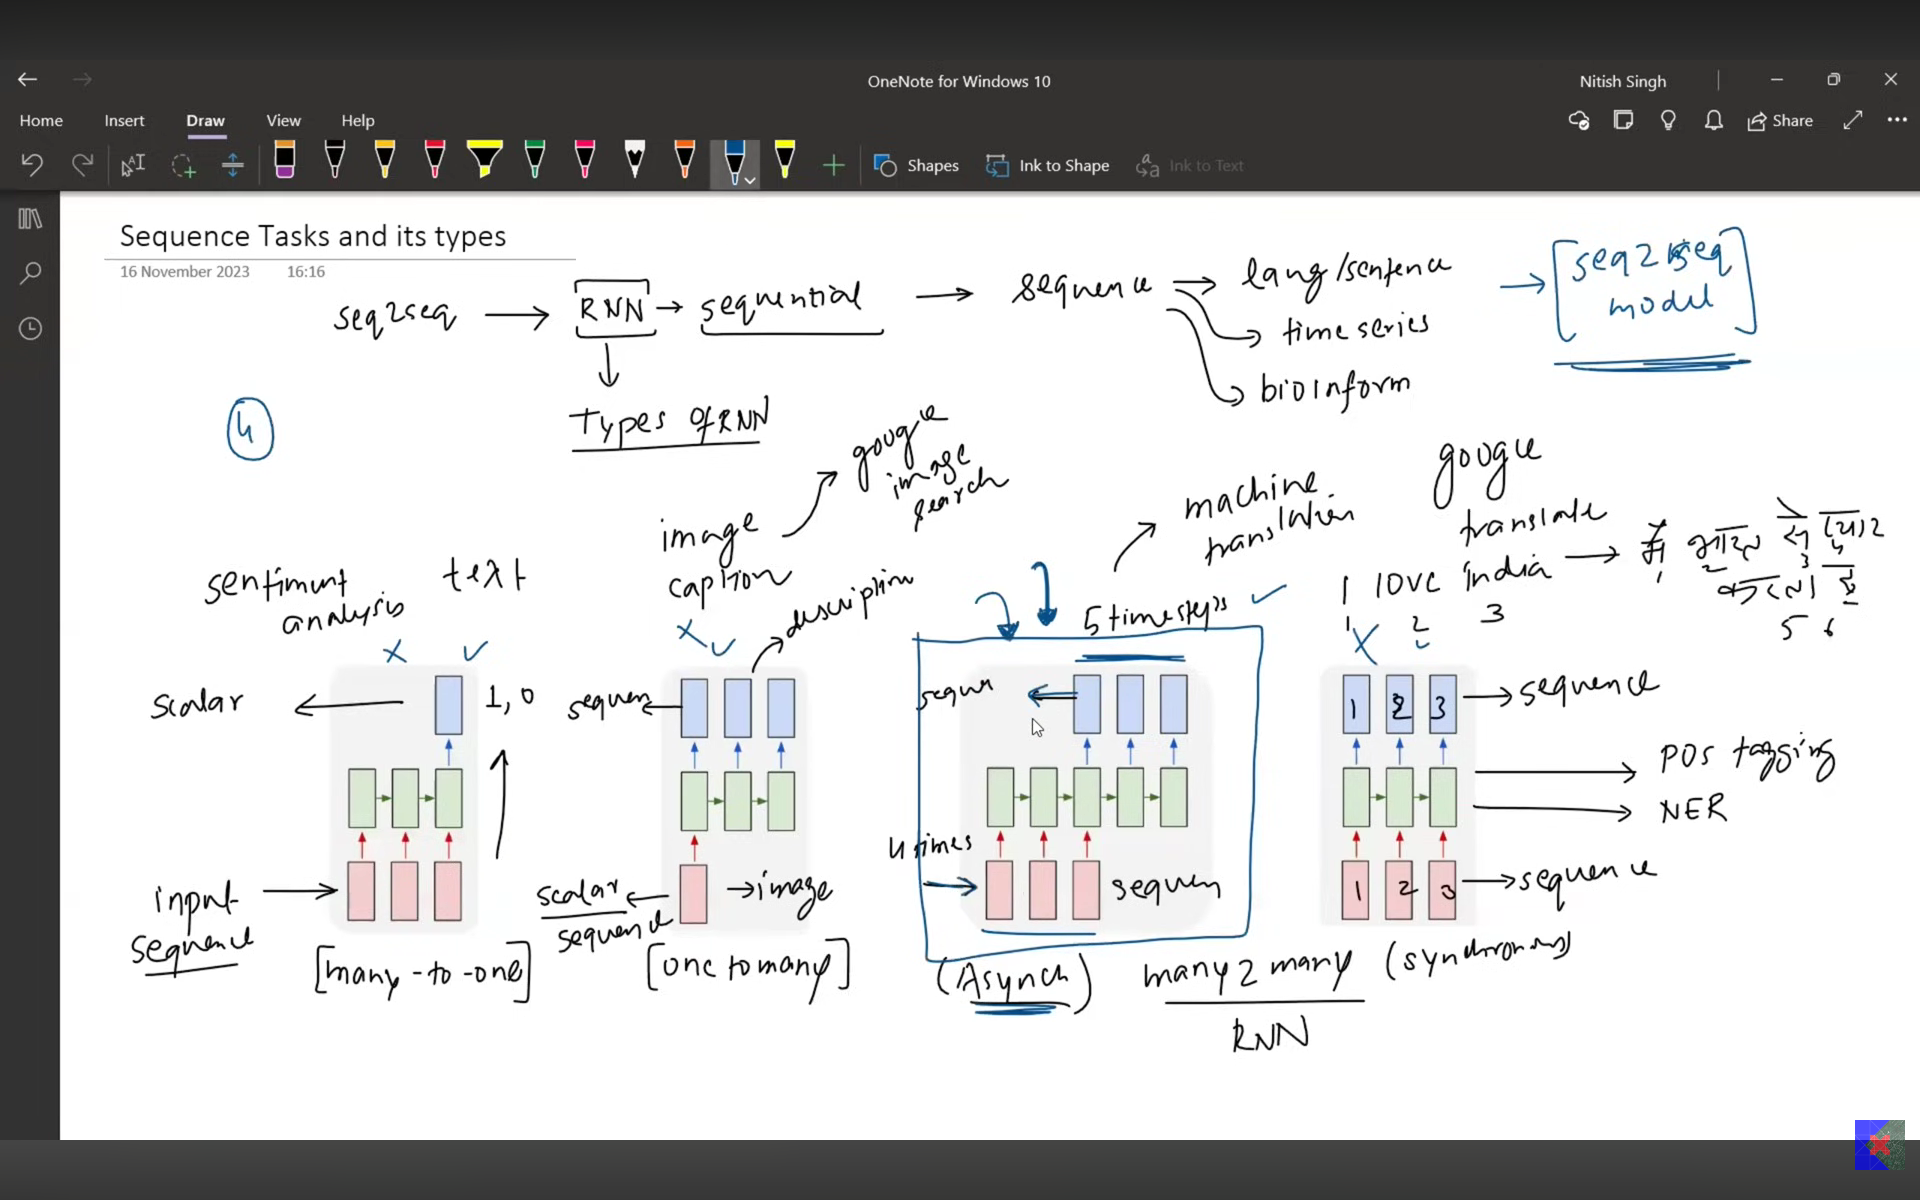

# Types of RNNs
1. **Many-to-One**: This type of RNN takes a sequence of inputs and produces a single output. It is commonly used in tasks like sentiment analysis, where the input is a sequence of words and the output is a sentiment label (positive, negative, or neutral).

2. **One-to-Many**: In this type of RNN, a single input is used to generate a sequence of outputs. It is often employed in tasks like image captioning, where an image is provided as input and the model generates a descriptive caption as output.

3. **Many-to-Many**: This type of RNN takes a sequence of inputs and produces a sequence of outputs.

    1. **Synchronous Many-to-Many**: In this case, the input and output sequences are of the same length. It is commonly used in tasks like Part-of-Speech tagging, where each word in a sentence is assigned a corresponding tag.

    2. **Asynchronous Many-to-Many**: In this case, the input and output sequences can have different lengths. It is often used in tasks like machine translation, where a sentence in one language is translated into a sentence in another language, which may have a different number of words.

- So Seq-to-seq models were particularly designed to handle the problems that **Asynchronous Many-to-Many** RNNs solve. They are capable of taking an input sequence of variable length and producing an output sequence of variable length, making them suitable for tasks like machine translation, text summarization, and speech recognition.

- So here in this module, we will talk more about 3.2 type of architectures

# Sequence-to-Sequence Tasks

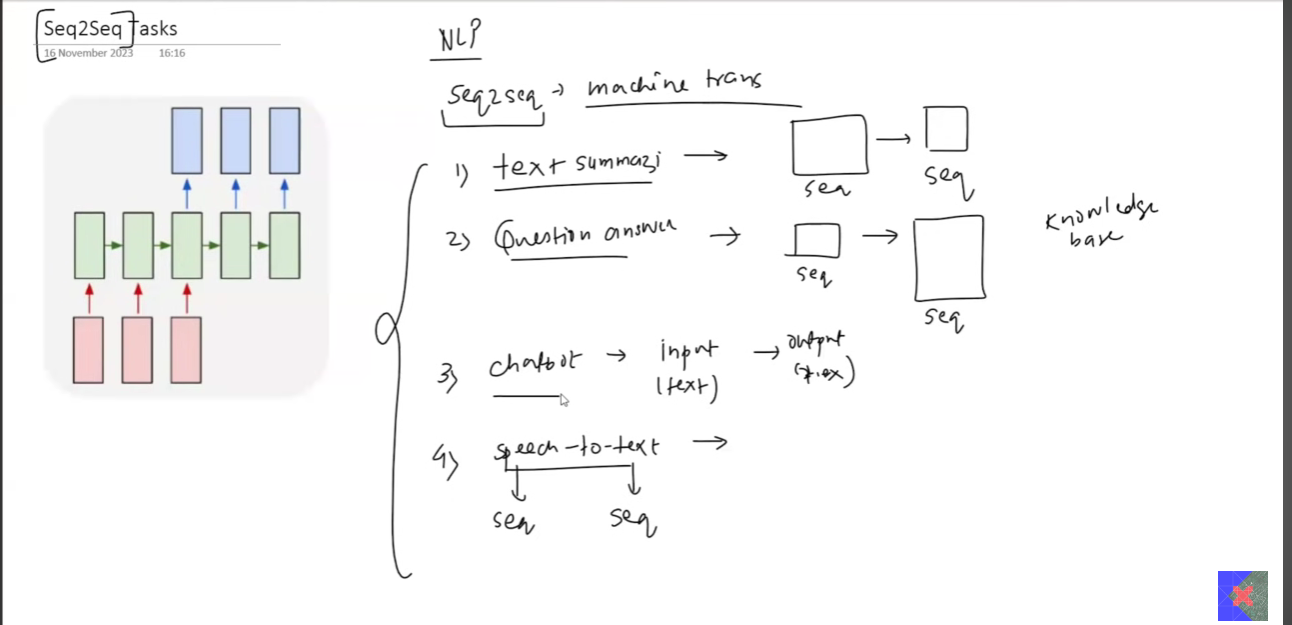


# History of Sequence-to-Sequence Models 
- The development of seq-to-seq models can be divided into 5 main stages:

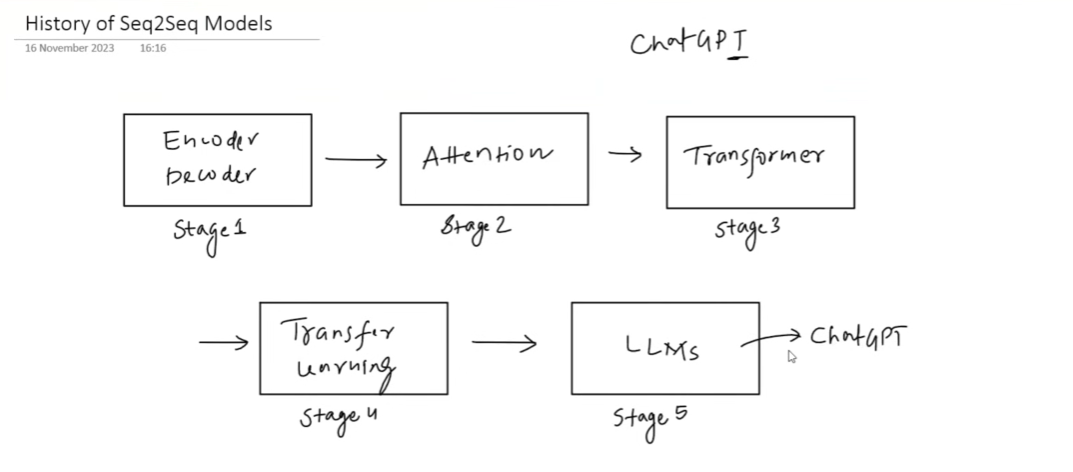

# Stage 1: Encoder-Decoder Architecture (2014)

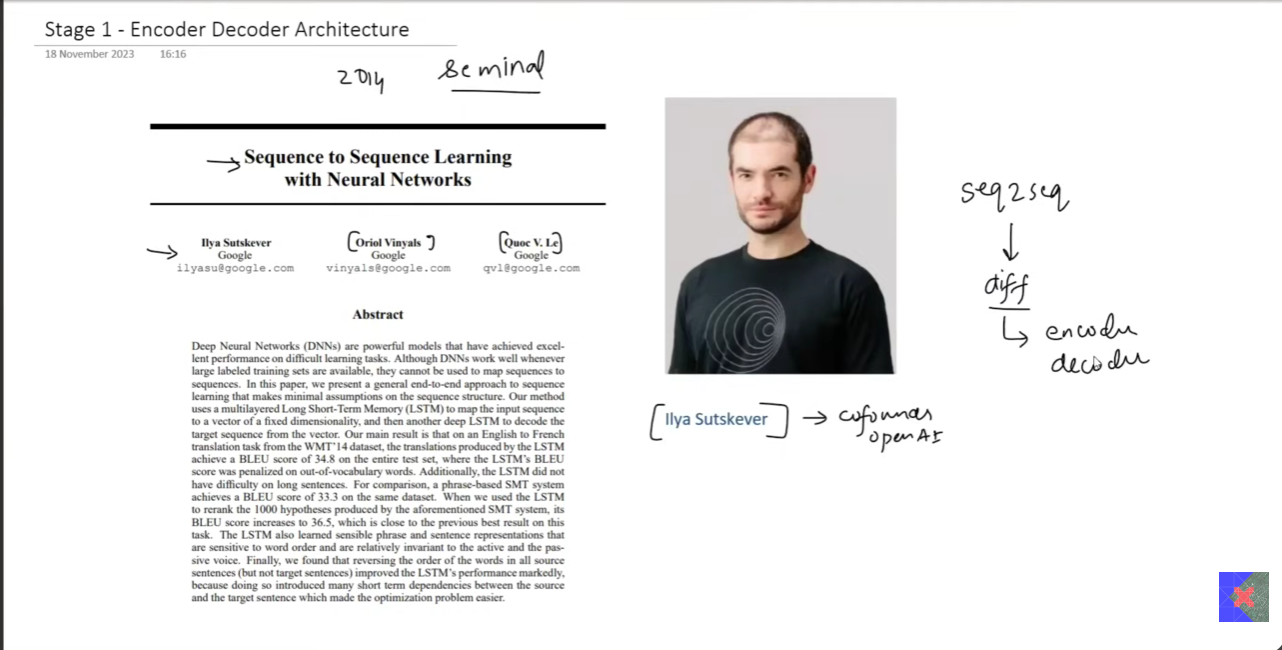

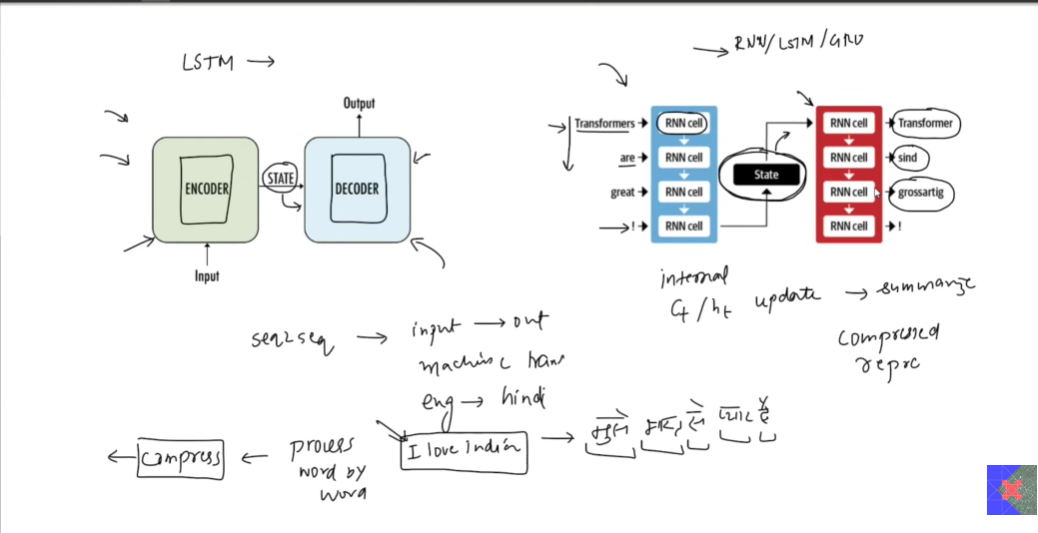

- The encoder-decoder architecture is a fundamental building block of seq-to-seq models. It consists of two main components: the encoder and the decoder.

- The encoder takes an input sequence and processes it to produce a fixed-length context vector that captures the relevant information from the input. The decoder then takes this context vector and generates an output sequence.

- Encoder and Decoder can be implemented using various types of neural networks, such as RNNs, LSTMs, or GRUs. The choice of architecture depends on the specific task and the characteristics of the input and output sequences.

- The downside of the encoder-decoder architecture is that it can struggle with long input sequences, it used to face memory loss problem..like the words that used to come in the beginning of the sentence are forgotten by the time the model reaches the end of the sentence. This is because the context vector is a fixed-length representation, which can lead to information loss for long sequences. 

- To solve this problem, attention mechanisms were introduced



# Stage 2: Attention Mechanism (2015)

- As we discussed that in the encoder-decoder architecture, the context vector is a fixed-length representation that can lead to information loss for long sequences. Specially for the words that used to come in the beginning of the sentence are forgotten by the time the model reaches the end of the sentence.

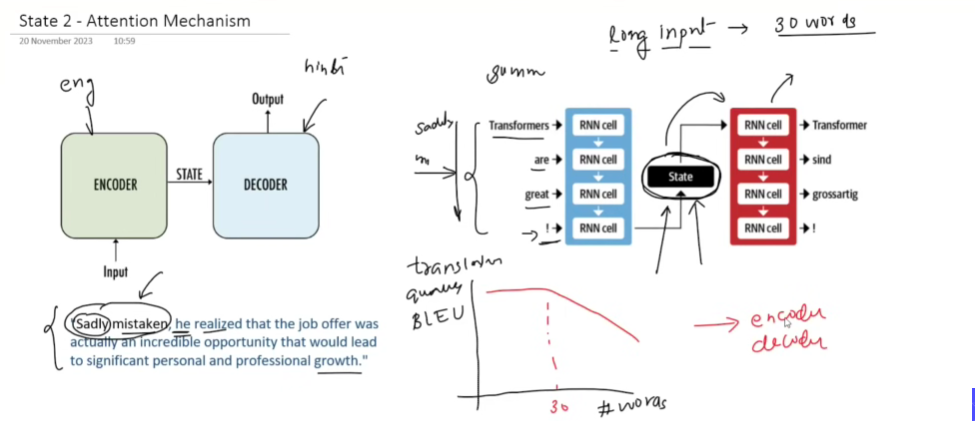

- For example in the above pic suppose the initial "Sadly mistaken" is forgotten by the time the model reaches the end of the sentence. Then it will change the whole sentiment of the sentence. So to solve this problem, attention mechanism was introduced.

-   BLEU (Bilingual Evaluation Understudy) is a metric used to evaluate the quality of machine-generated translations by comparing them to human reference translations. It measures the overlap of n-grams between the generated translation and the reference translation, providing a score that reflects how closely the machine translation matches human expectations.

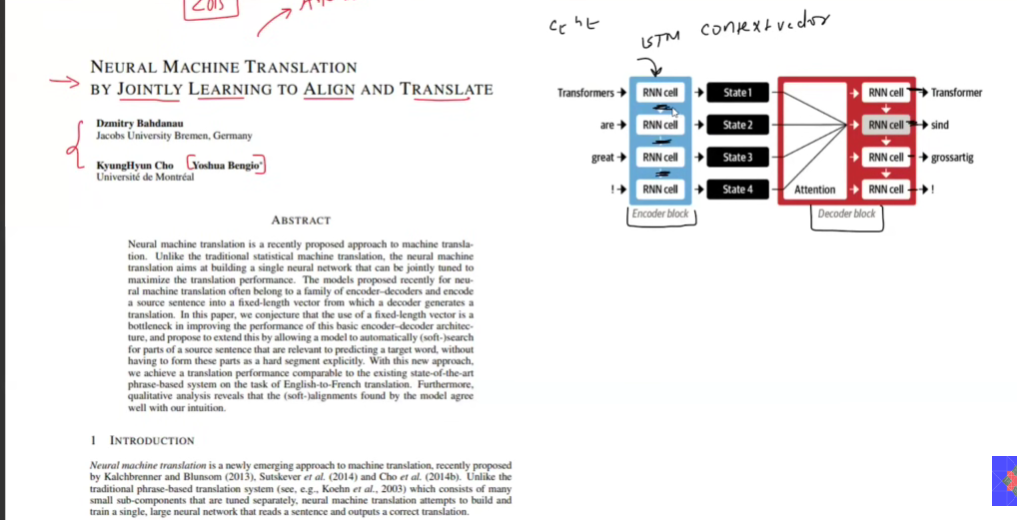

- The attention mechanism allows the decoder to focus on different parts of the input sequence at each time step, rather than relying solely on a fixed-length context vector. This enables the model to retain important information from earlier parts of the input sequence, improving its ability to generate accurate and contextually relevant outputs

- The attention mechanism helps that which hidden state of the encoder should be given more importance while generating the current word of the output sequence

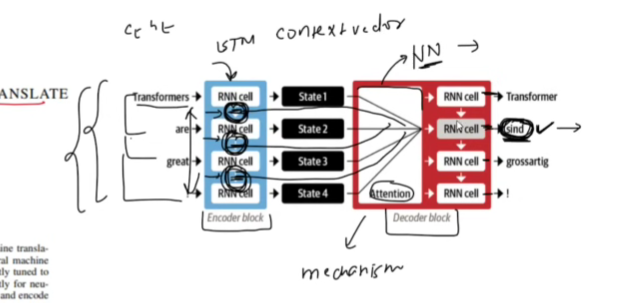

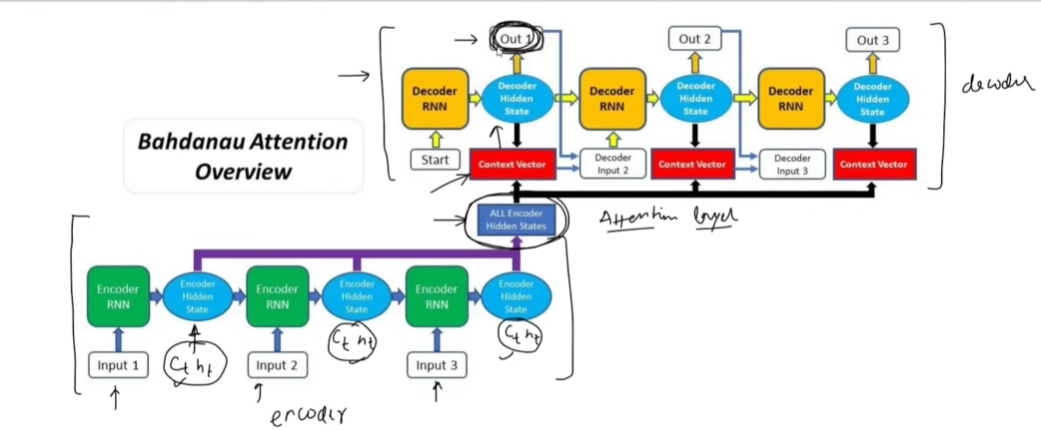

- The downside of the attention mechanism is that it can be computationally expensive, especially for long input sequences. The model needs to compute attention weights for each time step in the output sequence, which can lead to increased memory usage and slower training times. 

- Researcher identified that the main problem is we are using LSTM in the encoder and decoder. So it can do only sequential processing and this is the main reason for the slow training time. So to solve this problem, transformer architecture was introduced.

# Stage 3: Transformer Architecture (2017)

- Here they completely removed the LSTM or any RNN cells and replaced it with self-attention mechanism. 

- In the earlier encoder-decoder architecture, we were able to see input only in sequential manner. But in transformer architecture, we can see the input in parallel manner. So it is much faster than the earlier architecture.

- The only problem with transformer architecture was training it from scratch was very difficult. Because of the below reasons:
    1. Hardware requirements
    2. Better than encoder-decoder architecture but still takes time to train 
    3. Requires a lot of data to train from scratch (Biggest problem)

- So to solve this problem, comes transfer learning.
    

# Stage 4: Transfer Learning (2018)

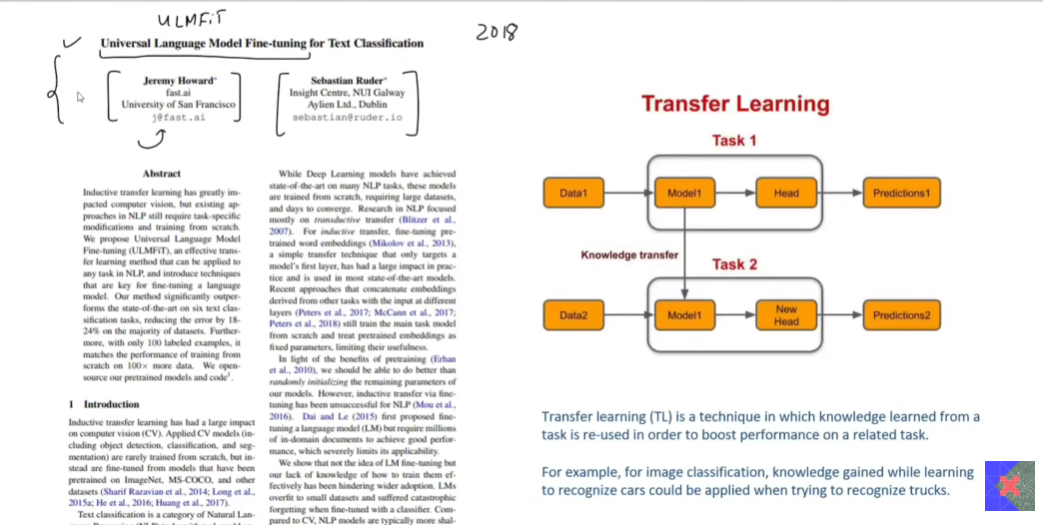

- Earlier tranfer learning was used in computer vision tasks. But in 2018, transfer learning was introduced in NLP tasks.

- They gave a framework named Universal Language Model Fine-tuning (ULMFiT) which is a transfer learning method for NLP tasks. It allows pre-trained language models to be fine-tuned on specific downstream tasks, enabling better performance with limited labeled data.

- Transfer Learning have 2 main steps:
    1. Pre-training: In this step, a language model is trained on a large corpus of text data to learn general language patterns and representations. This pre-trained model captures the statistical properties of the language and can be used as a starting point for various NLP tasks.
    
    2. Fine-tuning: In this step, the pre-trained language model is further trained on a smaller, task-specific dataset to adapt it to the specific requirements of the downstream task. This allows the model to leverage the knowledge gained during pre-training while also learning task-specific features.

### Reason behind why Transfer Learning was not used in NLP tasks before 2018

1. Task specificity: NLP have wide range of tasks, each with its own specific requirements and challenges. Pre-trained models may not generalize well to all tasks, leading to suboptimal performance.

    - But they tried to train a model for Machine Translation task and then used the same model for Other NLP tasks like Sentiment Analysis, Text Summarization, etc. But the performance was not good because the model was trained for a specific task and it was not able to generalize well to other tasks. and also the below point was also a reason for not using transfer learning in NLP tasks before 2018.

2. Data availability: NLP tasks often require large amounts of labeled data for training, and pre-trained models may not have been available or suitable for all tasks.

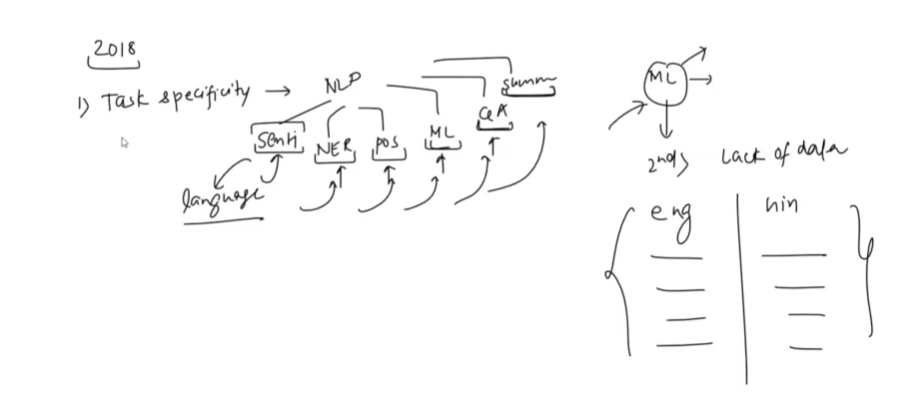

### What changed in 2018 that made transfer learning popular in NLP tasks?

- In the ULMFiT paper, they didn't use **Machine Translation** task for **pre-training**. Instead, they used a **language modeling** task for pre-training.

- **Language Modelling**: 
    - Language modeling is a fundamental task in natural language processing (NLP) that involves predicting the next word or token in a sequence given the previous words or tokens. It is a generative task that aims to capture the statistical properties and patterns of a language.

### Profit of using Language Modelling for Pre-training

1. **Rich feature learning**: Language modeling allows the model to learn rich representations of language, capturing syntactic and semantic patterns that can be useful for a wide range of NLP tasks. Sometimes good model also learns common sense knowledge about the world, which can be beneficial for downstream tasks.

2. **Huge availavility of data**: 
    - In machhine translation we needed Labelled data as it was a supervised task.
    - But in language modeling, we don't need labelled data as it is an unsupervised task. So we can use huge amount of data for pre-training the model.

### ULMFiT Architecture

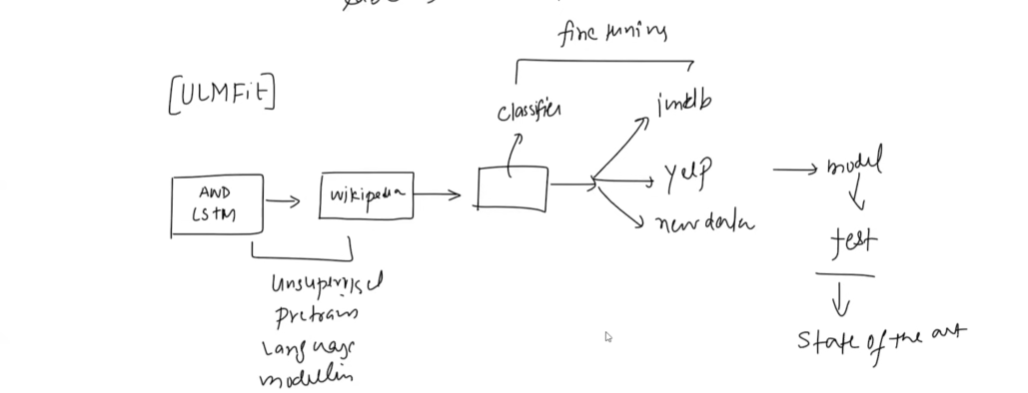

- They didn't use transformer architecture for ULMFiT. Instead, they used AWD-LSTM architecture for ULMFiT.

- Most probably they didn't use transformer architecture because of the below reasons:
    1. Transformer architecture was introduced in 2017 and it was very new at that time. So they didn't have much knowledge about it.
    2. They were not able to train transformer architecture on a single GPU because of its huge number of parameters. So they used AWD-LSTM architecture which was much smaller than transformer architecture and they were able to train it on a single GPU.

- So, by 2018 we have 2 poweful architectures for NLP tasks:
    1. Transformer (as a architecture for seq-to-seq problems)
    2. ULMFiT (as a training framework)

# Stage 5: LLMs (2018 - Present)

- In 2018 2 Language Models (Trained for next word prediction) were introduced which were trained on huge amount of data and they were able to generate human like text. These models are called Large Language Models (LLMs).
    1. BERT (Bidirectional Encoder Representations from Transformers): BERT is a transformer-based model that was introduced by Google in 2018. It is designed to pre-train deep bidirectional representations by jointly conditioning on both left and right context in all layers. BERT has achieved state-of-the-art performance on a wide range of NLP tasks, including question answering, sentiment analysis, and named entity recognition.
    2. GPT (Generative Pre-trained Transformer): GPT is a transformer-based model that was introduced by OpenAI in 2018. It is designed to pre-train a language model on a large corpus of text data and then use it for various downstream tasks such as text generation, translation, and summarization.

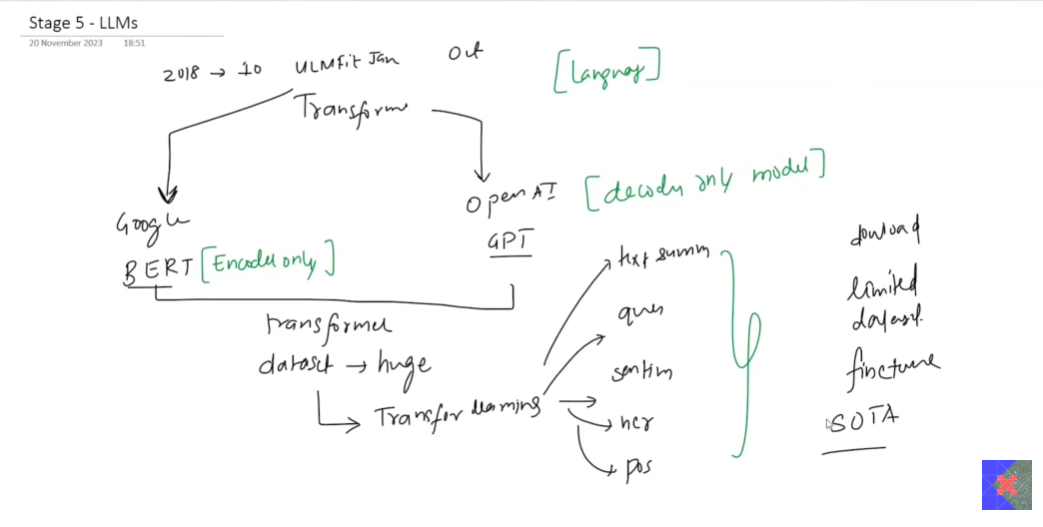

- So now anyone can use these pre-trained models for their own NLP tasks. They just need to fine-tune these models on their own dataset and they will get state-of-the-art performance on their own NLP tasks.

- They were traind on huge amount of data and had large number of parameters. So peopele started calling them **Large Language Models**(LLMs) instead of just Language Models.

### When does a Language Model become a Large Language Model? / Qualities of LLMs

1. **Data**: A language model is considered a large language model when it is trained on a massive amount of data

2. **Hardware**: A language model is considered a large language model when it requires significant computational resources to train and deploy, such as multiple GPUs or TPUs.

3. **Training Time**: A language model is considered a large language model when it takes a long time to train, often requiring weeks or months of training on high-performance hardware.

4. **Cost**: Hardware + electricity + experts

5. **Energy Consumption**: A language model is considered a large language model when it consumes a significant amount of energy during training and inference, which can have environmental implications.

# The Grand Finale- ChatGPT

- GPT-3 (Generative Pre-trained Transformer 3) is a state-of-the-art language model developed by OpenAI.

- ChatGPT is a chatbot application built using the GPT model

### Major steps on turning GPT into ChatGPT

1. **RLHF (Reinforcement Learning with Human Feedback)**: This step involves supervised fine-tuning the GPT model using reinforcement learning techniques, where human feedback is used to guide the model's responses. This helps improve the quality and relevance of the generated text.

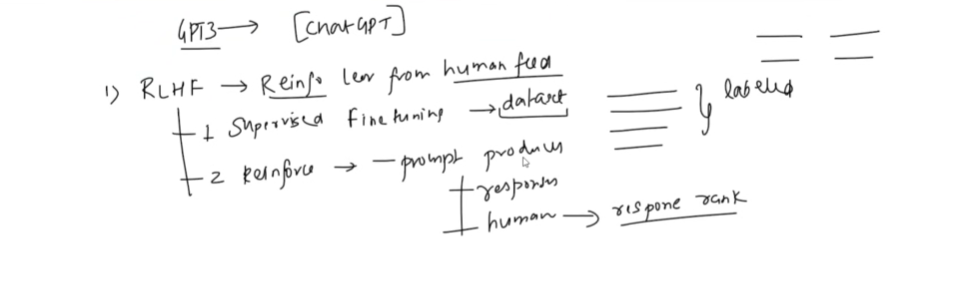

2. **Safety and Ethical Guidelines**: This step involves incorporating safety and ethical guidelines into the model to ensure that it generates text that is safe, appropriate, and aligns with societal values.

3. **Improvement in Contextual Understanding**: This step involves enhancing the model's ability to understand and maintain context in conversations, allowing it to generate more coherent and contextually relevant responses.

4. **Dialogue Specific Training**: ChatGPT was supervised fine-tuned on a dataset of conversations, which helps it generate more natural and engaging responses in a conversational context.

5. **Continuous Learning and Updates**: ChatGPT is continuously updated and improved based on user feedback and new data, allowing it to adapt to changing language patterns and user needs over time.